# `Column` — full design walkthrough

This notebook exercises the **entire public API** of the `Column` element of
`design/` (ACI 318‑25), following one **canonical 12‑step flow**. Every element
— `Beam`, `Column`, `Wall`, `BeamColumnJoint` — shares this same skeleton, so the
*architecture* is identical and only the **physics** changes.

> **Rational structure.** The element is an immutable object. You *create* it,
> *run* it to cache capacities, *review* a given reinforcement against demands,
> let it *design* a proposal, and *adopt* that proposal by producing a **new**
> element. Reporting and plotting sit on top. The shared base class
> `design.common.element_base.ElementBase` provides the parts that are identical
> across elements (`apply`, `set_units`); the runtime `Element` protocol
> (`design.common.contracts`) is the canonical `isinstance` test.

### The 12‑step contract

| Step | Call | Purpose |
|------|------|---------|
| 1 | `Concrete(...)`, `Steel(...)` | materials (MPa) |
| 2 | `Column.rectangular(...)` | **create** — every input argument shown |
| 3 | `el.run()` | lazy‑compute + cache capacity (returns `self`) |
| 4 | `el.capacity()` | capacity of the **as‑built** reinforcement |
| 5 | `el.demands(...)` | build the load set (display units → internal) |
| 6 | `el.check(demands)` | **review** the current rebar → PASS/FAIL |
| 7 | `el.design(demands)` | automatic **proposal** (multiple modes) |
| 8 | `results.envelope.<field>` | read the result **explicitly** (no magic) |
| 9 | `el.evolve(p)` / `el.apply(p)` | adopt → **new immutable** element |
| 10 | `report()` / `summary()` / `set_units()` / `print_final()` | reporting |
| 11 | `el.plot.*` | plotting |
| 12 | `el.run_optimize(demands)` | sweep detailing alternatives |

**Physics of this element.** A column is a **P‑M‑M + shear + confinement** member (ACI §10, §18.7). `run()` builds the full **biaxial interaction surface**; design details two confinement zones (`lo` and the middle zone) with a per‑direction hoop picker.

**By‑design exceptions.** The transverse steel is **directional** (`Av_x`, `Av_y`); the design produces two hoop sets per column. `hx` (§18.7.5.2) limits the horizontal bar spacing.

> **Internal units (non‑negotiable):** stress = MPa, length = mm, force = kN,
> moment = kN·m, area = mm². The `units=` argument only controls *presentation*.


## Step 1 — Materials

In [1]:
# Notebook setup: inline figures, repo on sys.path, silence the metre→mm warning
%matplotlib inline
import sys, pathlib, warnings
warnings.simplefilter("ignore", DeprecationWarning)

# Make `design` importable whether or not the repo is pip-installed:
_root = pathlib.Path.cwd().resolve()
while _root != _root.parent and not (_root / "design" / "__init__.py").is_file():
    _root = _root.parent
if (_root / "design").is_dir() and str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from design.common.materials import Concrete, Steel
from design.columns.column import Column

concrete = Concrete(fc=28.0)
steel = Steel(fy=420.0)
concrete, steel

(Concrete(fc=28.0, unit_weight=24.0, lightweight=False, sand_lightweight=False),
 Steel(fy=420.0, Es=200000.0, fu=None, grade=60, density=7850.0))

## Step 2 — Create the column

`Column.rectangular(...)` builds the section with perimeter bars and the hoop cage. `n_legs_x` / `n_legs_y` are the hoop legs resisting shear in each direction.

In [2]:
col = Column.rectangular(
    b=500, h=500, clear_cover=40,     # geometry (mm)
    concrete=concrete, steel=steel,
    n_x=4, n_y=4, db_long=25,         # longitudinal grid
    db_stirrup=10,                    # hoop diameter
    n_legs_x=4, n_legs_y=4,           # legs per direction
    s_stirrup=100,                    # hoop spacing (mm)
    lu=3000.0,                        # unbraced length (mm)
    k=1.0, spiral=False, seismic=True,
    hx=150.0,                         # max horizontal bar spacing
    label="C-501",
)
col

Column(label='C-501', section=500x500 mm, fc=28.00 N/mm^2, units=N_mm_C, run=no)

## Step 3 — `run()`

Builds the PMM surface and caches the axial limits (`Po`, `To`, `phi_Pn_max`) and the directional shear capacities.

In [3]:
col.run()
print(f"Po = {col.Po:.0f} kN   To = {col.To:.0f} kN   phi_Pn_max = {col.phi_Pn_max:.0f} kN")
print(f"phi_Vn_x = {col.phi_Vn_x:.0f} kN   phi_Vn_y = {col.phi_Vn_y:.0f} kN")

Po = 8284 kN   To = -2474 kN   phi_Pn_max = 4308 kN
phi_Vn_x = 597 kN   phi_Vn_y = 597 kN


## Step 4 — `capacity()`

The biaxial PMM snapshot. The `phi_Mn` proxy is queryable by angle and axial load: `col.phi_Mn.at(Pu=..., angle=...)`.

In [4]:
cap = col.capacity(biaxial=True)
print(f"phi_Vn = {cap.phi_Vn:.0f} kN")
print(f"peak phi_Mn @0°  = {col.phi_Mn.peak(angle=0):.0f} kN·m")
print(f"peak phi_Mn @90° = {col.phi_Mn.peak(angle=90):.0f} kN·m")
print(f"phi_Mn at Pu=1500 kN, 0° = {col.phi_Mn.at(Pu=1500, angle=0):.0f} kN·m")

phi_Vn = 597 kN
peak phi_Mn @0°  = 540 kN·m
peak phi_Mn @90° = 540 kN·m
phi_Mn at Pu=1500 kN, 0° = 487 kN·m


## Step 5 — `demands(...)`

A column demand is a single resolved set: axial `Pu`, biaxial moments `Mux`/`Muy`, and shears `Vux`/`Vuy`.

In [5]:
demands = col.demands(Pu=1500, Mux=300, Muy=150, Vux=120, Vuy=120)
print(f"Pu={demands.Pu:.0f} kN  Mux={demands.Mux:.0f}  Muy={demands.Muy:.0f} kN·m")

Pu=2 kN  Mux=0  Muy=0 kN·m


## Step 6 — `check(demands)`

Checks the biaxial PMM ratio, the directional shear, `Ash`, `hx` and the spacing in `lo`.

In [6]:
chk = col.check(demands)
print(f"ratio_pmm = {chk.ratio_pmm:.2f}   ratio_shear = {chk.ratio_shear:.2f}   passed = {chk.passed}")
chk.summary()

ratio_pmm = 0.00   ratio_shear = 0.80   passed = False
=== Column check ===
  PMM            : ratio = 0.000    [PASS]
  Shear X        : ratio = 0.804    (Vu=0.000, Ve=0.804)    [PASS]
  Shear Y        : ratio = 0.804    (Vu=0.000, Ve=0.804)    [PASS]
  Ash X (short)  : ratio = 1.116    prov=314 / req(D=350, C=350 mm^2)    [FAIL]
  Ash Y (long)   : ratio = 1.116    prov=314 / req(D=350, C=350 mm^2)    [FAIL]
  hx             : x=140, y=140 mm    [PASS]
  s (confined)   : prov=100, max=125 mm    [PASS]
  ---
  passed         : False
  ---
  Steel quantities (kg/m^3 of concrete):
    rho_long  =  184.96
    rho_trans =   82.86
    rho_total =  267.82
  Notes:
    - Ash insufficient -- X: prov 314 / req 350, Y: prov 314 / req 350 mm^2.


## Step 7 — `design(demands)`

Four modes again. The **capacity** mode builds `Mpr_x`/`Mpr_y`, the design shears `Ve`, and applies the `Vc = 0` rule (§18.7.6.2.1) where seismic shear dominates and axial is light.

In [7]:
results = col.design(demands, clear_cover=40)
col.print_design(results)


  COLUMN DESIGN -- C-501    (units: N_mm_C)
  Section 500x500 mm    lu = 3000 mm    seismic = True
  Max legs (from longitudinal bars):  ||X = 4    ||Y = 4
  Hoop schedule: [10, 12, 16]

------------------------------ [  DEMAND  ] ------------------------------
  lo  (confined zone, Sec.18.7.5):
    phi12  legs=(4,4)  s = 100 mm    lo = 500 mm
    Ash    req (350, 350)  prov (452, 452 mm^2)
    Av/s   req (0.001, 0.001) mm^2/mm
    hx     x = 140, y = 140 mm   hx_ok = True
    phiVn  x = 641261.9, y = 641261.9 N
    Mpr    x = 720038958.7, y = 720038958.7 N.mm
    Ve_cap x = 480026.0, y = 480026.0 N
    ratio  Ve/phiVn  x = 0.75, y = 0.75    (capacity)
    ratio  Vu/phiVn  x = 0.00, y = 0.00    (demand)
    ratio  PMM       = 0.00    [PASS]
    Sec.18.7.6.2.1  Vc=0:  x = True, y = True
  middle  (Sec.18.7.5.5 -- Av/s only):
    phi10  legs=(2,2)  s = 120 mm
    Av/s   req (0.000, 0.000) mm^2/mm
    Av     prov (157, 157 mm^2)
    phiVn  x = 337350.3, y = 337350.3 N
    ratio  Vu/phiVn

## Step 8 — Read the result explicitly

In [8]:
env = results.envelope
print(f"mode           = {env.mode}")
print(f"hoops          = {env.n_legs_x}×{env.n_legs_y} legs φ{env.db_hoop:.0f}")
print(f"spacing lo/mid = {env.spacing_confined:.0f} / {env.spacing_middle:.0f} mm")
print(f"Ash x/y req    = {env.ash_required_x:.0f} / {env.ash_required_y:.0f} mm²")

mode           = envelope
hoops          = 4×4 legs φ12
spacing lo/mid = 100 / 120 mm
Ash x/y req    = 350 / 350 mm²


## Step 9 — `evolve()` / `apply()`

In [9]:
col2 = col.evolve(env)
assert col2 is not col
_ = col.apply(env)
print(f"evolved phi_Vn_x = {col2.run().phi_Vn_x:.0f} kN")

evolved phi_Vn_x = 793 kN

## Step 10 — Reporting

In [10]:
print("report keys =", sorted(col2.report()))
col2.set_units("kN_m_C")
col2.summary()
col2.print_final(env, demands=demands)

report keys = ['capacity', 'label', 'materials', 'params', 'rebar', 'section', 'units']
=== C-501 ===  (units: kN_m_C)
Section : 0.500x0.500 m
Materials: fc = 28000.00 kN/m^2, fy = 420000.00 kN/m^2
Rebar   : 12 bars, As = 5890 mm^2, rho = 2.36%
Po      : 8283.8 kN
To      : -2474.0 kN
phiPn,max : 4307.6 kN
phiVn (x/y): 793.1 / 793.1 kN
max phiMn @ theta=0deg  : 540.3 kN.m
max phiMn @ theta=90deg : 540.3 kN.m
Hoops   : phi12  legs=(4,4)  s=0.100 m
Steel quantities (kg/m^3 of concrete):
  rho_long  = 184.96
  rho_trans = 119.32
  rho_total = 304.28

  COLUMN -- FINAL DESIGN   |   C-501   |   units: kN_m_C
  Section          : 0.500 x 0.500 m   clear_cover = 0.040 m
  Materials        : fc' = 28000.00 kN/m^2    fy = 420000.00 kN/m^2
  Longitudinal     : 12 bars   As = 5890 mm^2   rho_geom = 2.36 %
----------------------------------------------------------------------------
  Hoops -- lo (Sec.18.7.5):
    phi12   legs = (short=4, long=4)   s = 0.100 m   lo = 0.500 m
    Av provided      : 

## Step 11 — Plotting

The dashboard plus a constant‑`Pu` slice of the biaxial surface with the demand point overlaid.

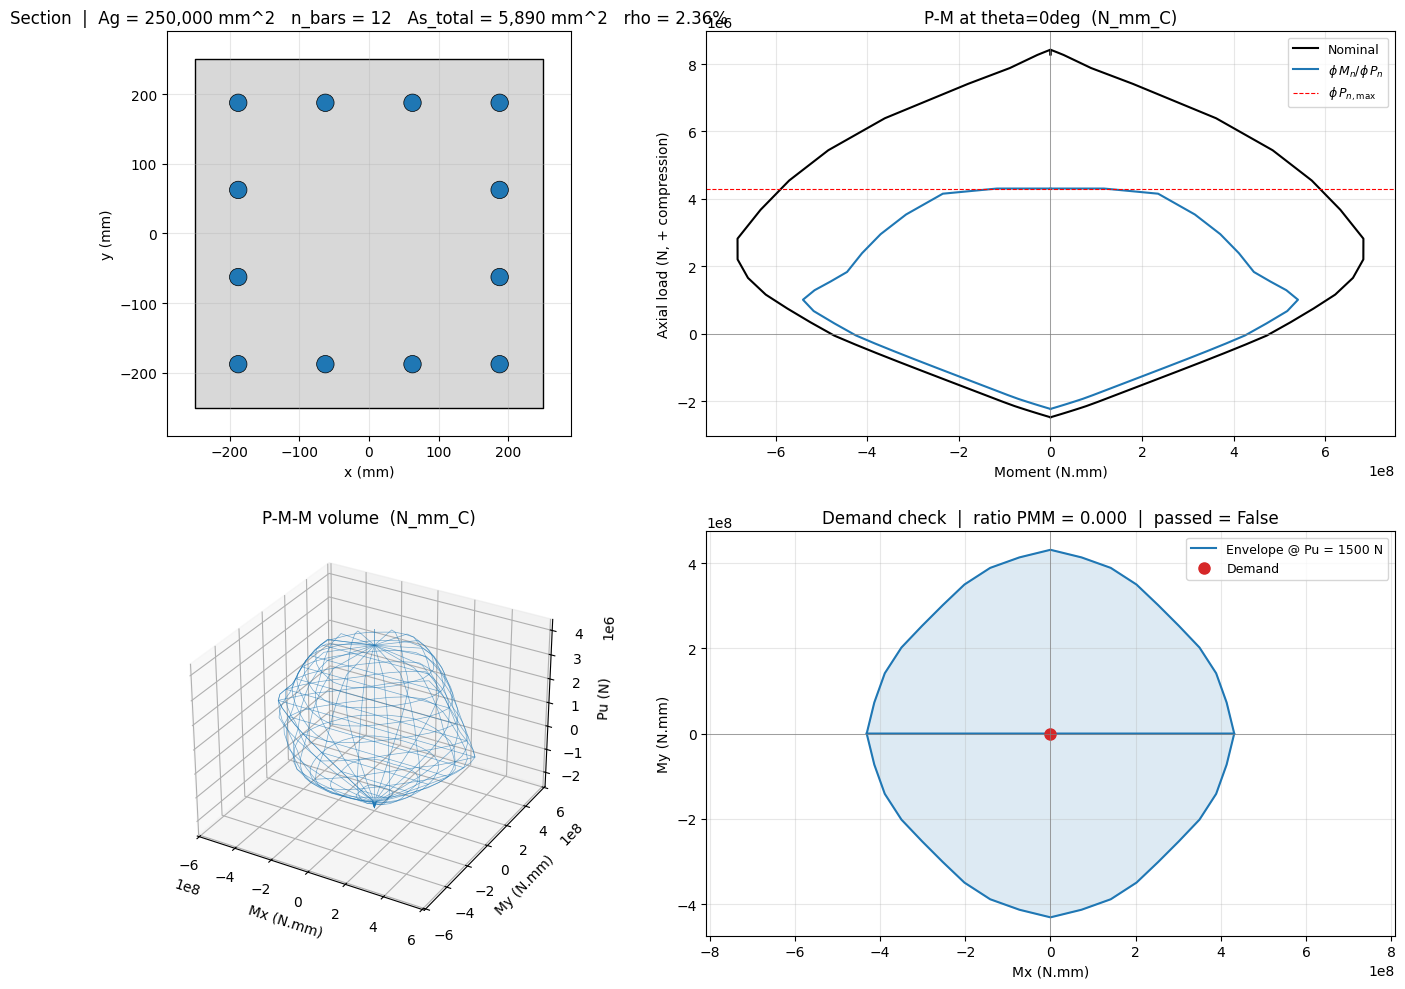

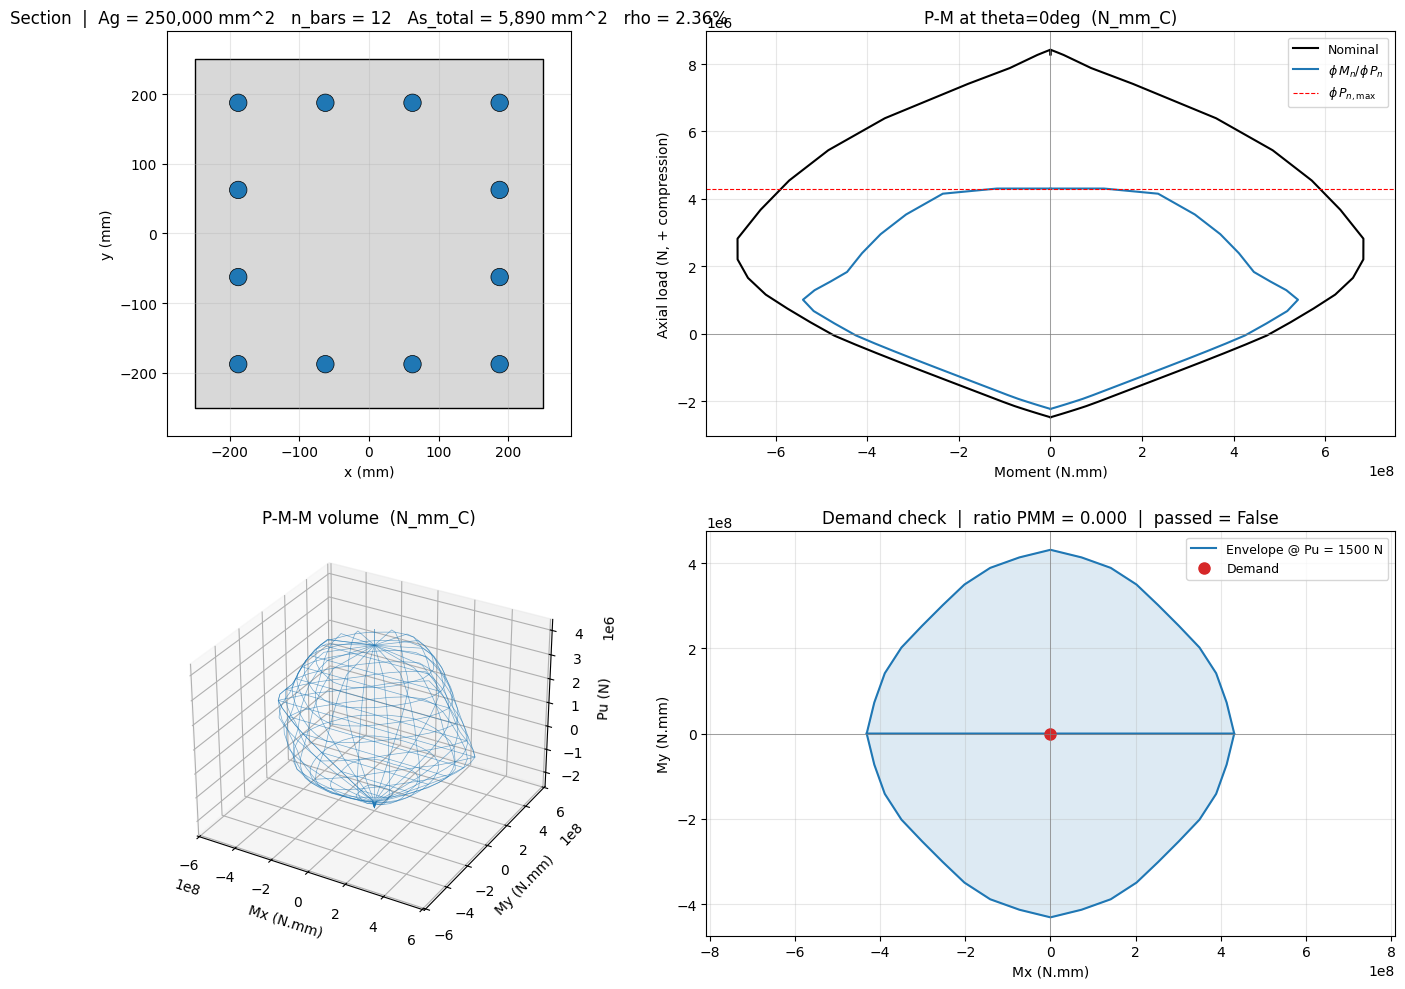

In [11]:
fig = col.plot.dashboard(demands=demands)
fig

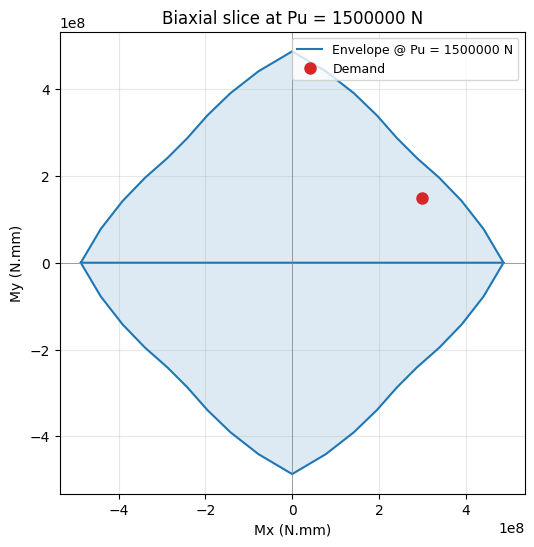

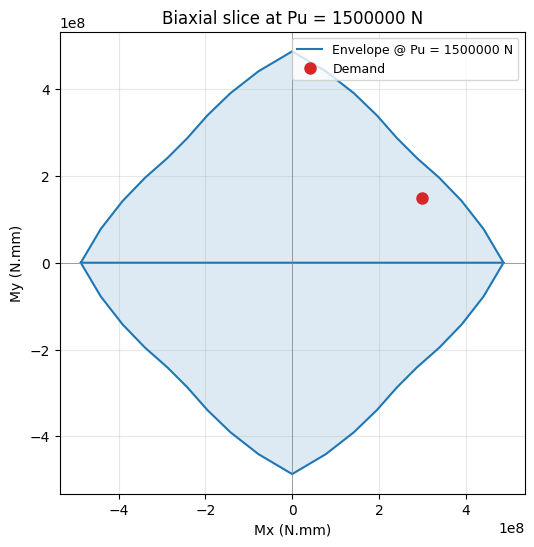

In [12]:
ax = col.plot.pmm_slice(Pu=1500, demand=(300, 150))
ax.figure

## Step 12 — `run_optimize(demands)`

In [13]:
alts = col.run_optimize(demands)
print(f"{len(alts)} alternatives; best rho_total = {alts[0].rho_total:.1f} kg/m³")

9 alternatives; best rho_total = 273.7 kg/m³


---
### Architecture recap

Identical 12‑step skeleton to the beam; the only differences are the **biaxial PMM surface**, the **two confinement zones** and the **directional** transverse steel.